# Optimization

In notebooks 1, 2, and 3, we explored tokenizers, fine-tuned transformer models, and evaluated their performance.

This notebook investigates training optimization strategies by comparing different optimizers.

**Optimizers** determine how model parameters are updated during fine-tuning, with the aim of minimizing the training loss and improving generalization to unseen data.

We will compare the optimizers by measuring:
- Training and validation loss.
- Task-appropriate evaluation metrics, such as macro-F1, which gives each intent class equal weight.
- Training time and memory usage.
- Confidence calibration, using Expected Calibration Error (ECE).

**Training loss** and **macro-F1** measure different aspects of model performance: loss evaluates how well the model's predicted probabilities match the correct labels, while macro-F1 measures precision and recall across classes, giving each class equal weight.

Let's see how different optimizers affect classification quality and training efficiency!


## Install dependencies

In [ ]:
!pip install lion-pytorch schedulefree

##Prepare data
Let's use our Amazon intent dataset in Finnish and take the 10 most common intents like we did in notebook 2.

In [ ]:
from datasets import load_dataset

# load multilingual dataset
dataset = load_dataset("mteb/amazon_massive_intent")

# keep only Finnish examples
hf_train_dataset = dataset["train"].filter(
    lambda example: example["lang"] == "fi"
)

hf_validation_dataset = dataset["validation"].filter(
    lambda example: example["lang"] == "fi"
)

hf_test_dataset = dataset["test"].filter(
    lambda example: example["lang"] == "fi"
)

In [3]:
from collections import Counter

# Find the 10 most frequent classes in the Finnish TRAINING data
class_counts = Counter(hf_train_dataset["label"])

top_10_classes = [
    label for label, count in class_counts.most_common(10)
]

print("Top 10 Finnish classes:", top_10_classes)
print("Number of Finnish training examples:", len(hf_train_dataset))

Top 10 Finnish classes: ['calendar_set', 'play_music', 'weather_query', 'calendar_query', 'general_quirky', 'qa_factoid', 'news_query', 'email_query', 'email_sendemail', 'datetime_query']
Number of Finnish training examples: 11514


In [ ]:
# Keep ONLY those 10 classes in all three splits
hf_train_dataset_final = hf_train_dataset.filter(
    lambda example: example["label"] in top_10_classes
)

hf_val_dataset_final = hf_validation_dataset.filter(
    lambda example: example["label"] in top_10_classes
)

hf_test_dataset_final = hf_test_dataset.filter(
    lambda example: example["label"] in top_10_classes
)

Let's prepare the labels for our transformer model. It requires integers, but for readability, we want to be able to mpa them back to strings.

In [5]:
label2id = {
    "calendar_query": 0,
    "calendar_set": 1,
    "datetime_query": 2,
    "email_query": 3,
    "email_sendemail": 4,
    "general_quirky": 5,
    "news_query": 6,
    "play_music": 7,
    "qa_factoid": 8,
    "weather_query": 9,
}

id2label = {v: k for k, v in label2id.items()}

def map_labels(example):
    example["labels"] = label2id[example["label"]]
    return example

In [ ]:
hf_train_dataset_final = hf_train_dataset_final.map(map_labels)
hf_val_dataset_final = hf_val_dataset_final.map(map_labels)
hf_test_dataset_final = hf_test_dataset_final.map(map_labels)

Finally, let's tokenize the dataset and truncate the sequences to defined max length.

In [7]:
from datasets import Dataset

def _tokenize_function_helper(examples, tokenizer, truncation, max_length):
    kwargs = {
        "truncation": truncation,
        "padding": False
    }
    if max_length is not None:
        kwargs["max_length"] = max_length

    tokenized_inputs = tokenizer(
        examples["text"],
        **kwargs
    )
    # Explicitly add the 'labels' column back to the tokenized output
    tokenized_inputs["labels"] = examples["labels"]
    return tokenized_inputs

def tokenize_dataset(dataset, tokenizer, max_length=None):
    """
    Tokenizes the dataset.

    Sequences longer than max_length are truncated.
    No padding is performed here; padding should be handled dynamically
    when batches are created.
    """

    # Use remove_columns to ensure only tokenized inputs and labels are kept
    return dataset.map(
        lambda examples: _tokenize_function_helper(examples, tokenizer, True, max_length),
        batched=True,
        remove_columns=['text', 'label', 'lang'] # Remove original text, label, and lang columns
    )

In [ ]:
from transformers import AutoTokenizer

tokenizer_finbert = AutoTokenizer.from_pretrained("TurkuNLP/bert-base-finnish-cased-v1")
MAX_LENGTH = 512

train_tokenized = tokenize_dataset(hf_train_dataset_final, tokenizer_finbert, max_length=MAX_LENGTH)
val_tokenized = tokenize_dataset(hf_val_dataset_final, tokenizer_finbert, max_length=MAX_LENGTH)
test_tokenized = tokenize_dataset(hf_test_dataset_final, tokenizer_finbert, max_length=MAX_LENGTH)

## Fine-tune with optimizer

### How optimizers work

At the heart of nearly every optimizer lies a *gradient-based algorithm*, which uses backpropagation to calculate gradients and update model parameters iteratively to minimize the loss function. In other words, during training, the model makes predictions, calculates the loss, and uses gradients to update its weights so that the loss is reduced and predictions are more accurate.

In Notebook 2, the model was fine-tuned using Hugging Face `Trainer`, which uses **AdamW** by default. Here, let's compare the following optimizers:
- AdamW
- Lion
- Schedule-Free AdamW

The optimizer determines how these updates are made:

- **AdamW:** Uses information from previous gradients and their squared values to adjust the size and direction of parameter updates. It also uses decoupled weight decay to discourage excessively large weights and help regularize the model. A learning-rate scheduler is often used alongside AdamW to adjust the learning rate during training. We can consider this optimizer the baseline in our experiment.

- **Lion:** Uses the current gradient and information from previous gradients to decide how to update each parameter. Instead of adjusting each update based on the gradient's exact magnitude, it uses its sign to determine the update direction. This requires less optimizer-state memory than AdamW, but Lion often needs a smaller learning rate and different weight decay settings to achieve good results.

- **Schedule-Free AdamW:** Uses AdamW-style parameter updates together with weight averaging, without requiring a conventional learning-rate scheduler. Instead of following a predefined learning-rate schedule, it uses a schedule-free approach to update and average model weights during training. This can simplify training configuration, although performance still depends on the choice of hyperparameters


### Hyperparameters

Two important training hyperparameters are:

- **Learning rate:** Controls the size of the optimizer's parameter updates. You can think of it as the size of each "step" the model takes when adjusting its weights. A rate that is too high can make training unstable, while one that is too low can make learning slow or ineffective.

- **Weight decay:** Regularizes the model by discouraging excessively large weights, which can help reduce overfitting. The appropriate value depends on the model, dataset, and optimizer.

Additionally:

- **Learning-rate scheduler:** Changes the learning rate according to a predefined rule as training progresses. It works alongside the optimizer and determines how the learning rate changes over time. For example, a linear scheduler gradually decreases the learning rate during training, often after an initial warmup period.

In [9]:
# config
NUM_LABELS = 10
MODEL_NAME = "TurkuNLP/bert-base-finnish-cased-v1"

TRAIN_DATASET = train_tokenized
VAL_DATASET = val_tokenized
TEST_DATASET = test_tokenized

SEED = 45
PER_DEVICE_TRAIN_BATCH_SIZE = 16
NUM_TRAIN_EPOCHS = 5

WEIGHT_DECAY = 0.01
WEIGHT_DECAY_LION = 0.03  #for Lion should be 3-10x larger

LEARNING_RATE = 2e-5
LEARNING_RATE_LION = 5e-6  #for Lion should be 3-10x smaller

EVALUATION_STRATEGY = "epoch"

In [10]:
# Keep only the tensor fields required by the model
columns_to_keep = ["input_ids", "attention_mask", "labels"]
TRAIN_DATASET.set_format(type="torch", columns=columns_to_keep)
VAL_DATASET.set_format(type="torch", columns=columns_to_keep)

### Experimental setup

To make the comparison as fair and reproducible as possible, we will:
- Use the same training and validation data splits and batch size for all optimizers.
- Set a fixed random seed to improve reproducibility.
- Calculate epoch-level loss by weighting each batch's loss by its number of examples, so that a smaller final batch does not contribute as much as a full batch.
- Initialize each experiment from the same pretrained Finnish BERT model, with a newly initialized classification head.
- Train each model for the same number of epochs and evaluate it on the same validation set.

The optimizers may use different learning rates and weight decay values, as these can affect their performance. These settings will be documented for each experiment.

> Remember to switch to GPU for more efficient training!

In [11]:
import time
import torch
import numpy as np
import schedulefree

from lion_pytorch import Lion
from sklearn.metrics import f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
    set_seed,
)

benchmark_results = {}

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def train_with_optimizer(
    optimizer_name="adamw",
    model_name=MODEL_NAME,
    num_labels=NUM_LABELS,
    batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    epochs=NUM_TRAIN_EPOCHS,
    train_dataset=TRAIN_DATASET,
    val_dataset=VAL_DATASET,
    seed=SEED,
):
    optimizer_name = optimizer_name.lower()

    if optimizer_name not in {"adamw", "lion", "schedule_free"}:
        raise ValueError(f"Unknown optimizer: {optimizer_name}")

    # Optimizer-specific hyperparameters
    if optimizer_name == "lion":
        learning_rate = LEARNING_RATE_LION
        weight_decay = WEIGHT_DECAY_LION
    else:
        learning_rate = LEARNING_RATE
        weight_decay = WEIGHT_DECAY

    set_seed(seed)

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=data_collator,
    )

    val_loader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=data_collator,
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=num_labels,
        label2id=label2id,
        id2label=id2label,
    ).to(device)

    optimizer_classes = {
        "adamw": torch.optim.AdamW,
        "lion": Lion,
        "schedule_free": schedulefree.AdamWScheduleFree,
    }

    optimizer = optimizer_classes[optimizer_name](
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay,
    )

    # Linear learning-rate schedule for standard AdamW only
    scheduler = None

    if optimizer_name == "adamw":
        total_steps = len(train_loader) * epochs
        scheduler = get_linear_schedule_with_warmup(
            optimizer,
            num_warmup_steps=int(0.1 * total_steps),
            num_training_steps=total_steps,
        )

    train_losses = []
    val_losses = []
    val_macro_f1 = []

    # Reset peak GPU memory tracking
    if device.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats(device)

    total_training_time = 0.0

    for epoch in range(epochs):
        if device.type == "cuda":
            torch.cuda.synchronize()

        epoch_start = time.perf_counter()

        model.train()

        if optimizer_name == "schedule_free":
            optimizer.train()

        total_train_loss = 0.0
        total_train_examples = 0

        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}

            optimizer.zero_grad(set_to_none=True)

            outputs = model(**batch)
            loss = outputs.loss
            loss.backward()
            optimizer.step()

            if scheduler is not None:
                scheduler.step()

            n_examples = batch["labels"].size(0)
            total_train_loss += loss.item() * n_examples
            total_train_examples += n_examples

        train_loss = total_train_loss / total_train_examples
        train_losses.append(train_loss)

        # Validation
        if optimizer_name == "schedule_free":
            optimizer.eval()

        model.eval()

        total_val_loss = 0.0
        total_val_examples = 0
        all_preds = []
        all_labels = []

        # Save confidence and correctness for every validation example
        all_confidences = []
        all_correct = []

        with torch.inference_mode():
            for batch in val_loader:
                batch = {k: v.to(device) for k, v in batch.items()}

                outputs = model(**batch)

                n_examples = batch["labels"].size(0)
                total_val_loss += outputs.loss.item() * n_examples
                total_val_examples += n_examples

                # Convert logits into class probabilities
                probabilities = torch.softmax(outputs.logits, dim=-1)

                # Predicted class and its confidence
                confidences, predictions = probabilities.max(dim=-1)

                labels = batch["labels"]
                correct = predictions.eq(labels)

                all_preds.extend(predictions.cpu().tolist())
                all_labels.extend(labels.cpu().tolist())
                all_confidences.extend(confidences.cpu().tolist())
                all_correct.extend(correct.cpu().tolist())

        val_loss = total_val_loss / total_val_examples

        macro_f1 = f1_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0,
        )

        val_losses.append(val_loss)
        val_macro_f1.append(macro_f1)

        if device.type == "cuda":
            torch.cuda.synchronize()

        total_training_time += time.perf_counter() - epoch_start

        print(
            f"[{optimizer_name}] Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Macro-F1: {macro_f1:.4f}"
        )

    # Confidence metrics from the final epoch's model
    confidences = np.asarray(all_confidences)
    correct = np.asarray(all_correct, dtype=bool)

    mean_confidence = float(confidences.mean())
    accuracy = float(correct.mean())

    # Expected Calibration Error (ECE), using 10 equal-width bins
    ece = 0.0
    n_predictions = len(confidences)
    n_bins = 10

    for bin_idx in range(n_bins):
        lower = bin_idx / n_bins
        upper = (bin_idx + 1) / n_bins

        if bin_idx == n_bins - 1:
            in_bin = (confidences >= lower) & (confidences <= upper)
        else:
            in_bin = (confidences >= lower) & (confidences < upper)

        if in_bin.any():
            bin_accuracy = correct[in_bin].mean()
            bin_confidence = confidences[in_bin].mean()
            ece += (
                in_bin.sum() / n_predictions
            ) * abs(bin_accuracy - bin_confidence)

    # Identify best epochs
    best_loss_epoch = min(
        range(epochs), key=val_losses.__getitem__
    ) + 1

    best_f1_epoch = max(
        range(epochs), key=val_macro_f1.__getitem__
    ) + 1

    # Peak GPU memory
    peak_gpu_memory_mb = (
        torch.cuda.max_memory_allocated(device) / (1024 ** 2)
        if device.type == "cuda"
        else None
    )

    print(f"Training + validation time: {total_training_time:.2f} seconds")
    print(f"Mean prediction confidence: {mean_confidence:.4f}")
    print(f"Validation accuracy: {accuracy:.4f}")
    print(f"Expected Calibration Error: {ece:.4f}")

    if peak_gpu_memory_mb is not None:
        print(f"Peak GPU memory: {peak_gpu_memory_mb:.2f} MB")

    # Per-example validation predictions
    prediction_details = [
        {
            "true_label": true_label,
            "predicted_label": predicted_label,
            "confidence": float(confidence),
            "correct": bool(is_correct),
        }
        for true_label, predicted_label, confidence, is_correct
        in zip(all_labels, all_preds, all_confidences, all_correct)
    ]

    results = {
        "optimizer": optimizer_name,
        "model_name": model_name,
        "batch_size": batch_size,
        "epochs": epochs,
        "learning_rate": learning_rate,
        "weight_decay": weight_decay,
        "train_loss": train_losses,
        "val_loss": val_losses,
        "val_macro_f1": val_macro_f1,
        "best_loss_epoch": best_loss_epoch,
        "best_f1_epoch": best_f1_epoch,
        "training_time_seconds": total_training_time,
        "peak_gpu_memory_mb": peak_gpu_memory_mb,
        "mean_confidence": mean_confidence,
        "val_accuracy": accuracy,
        "ece": float(ece),
        "prediction_details": prediction_details,
    }

    benchmark_results[optimizer_name] = results

    return results

In [ ]:
# test AdamW
train_with_optimizer("adamw")

In [ ]:
from lion_pytorch import Lion

# test lion
train_with_optimizer("lion")

In [ ]:
# test schedule-free adamw
train_with_optimizer("schedule_free")

##Analyse results

Let's compare the optimizers using the following metrics:
- **Training loss:** How well the model fits the training data.
- **Validation loss:** How well the model performs on unseen validation data.
- **Macro-F1:** Measures classification performance across all intent classes, giving each class equal weight.
- **Accuracy:** The proportion of validation examples classified correctly.
- **Training time:** How long training and validation take.
- **Memory usage:** The peak GPU memory allocated during training.
- **Confidence calibration (ECE):** Measures how closely the model's prediction confidence matches its actual accuracy.

Which optimizer offers the best balance between training efficiency, resource usage, and classification performance?

In [15]:
def compare_optimization_results():
    if not benchmark_results:
        print("No results to compare. Run the optimizer experiments first!")
        return

    print("=== Optimizer Results ===")

    for name, data in benchmark_results.items():
        # Lowest training loss
        best_train_loss = min(data["train_loss"])
        best_train_epoch = data["train_loss"].index(best_train_loss) + 1

        # Lowest validation loss
        best_val_loss = min(data["val_loss"])
        best_val_epoch = data["val_loss"].index(best_val_loss) + 1

        # Highest validation macro-F1
        best_f1 = max(data["val_macro_f1"])
        best_f1_epoch = data["val_macro_f1"].index(best_f1) + 1

        print(f"\n{name}")
        print(f"  Learning rate:                 {data['learning_rate']:.1e}")
        print(f"  Weight decay:                  {data['weight_decay']:.3f}")
        print(
            f"  Best training loss:            {best_train_loss:.4f} "
            f"(epoch {best_train_epoch})"
        )
        print(
            f"  Best validation loss:          {best_val_loss:.4f} "
            f"(epoch {best_val_epoch})"
        )
        print(
            f"  Best validation macro-F1:      {best_f1:.4f} "
            f"(epoch {best_f1_epoch})"
        )

        # Training and validation time
        print(
            f"  Training + validation time:    "
            f"{data['training_time_seconds']:.2f} seconds"
        )

        # Peak GPU memory usage
        if data["peak_gpu_memory_mb"] is not None:
            print(
                f"  Peak GPU memory usage:         "
                f"{data['peak_gpu_memory_mb']:.2f} MB"
            )
        else:
            print("  Peak GPU memory usage:         Not available (CPU)")

        # Prediction confidence and calibration
        print(
            f"  Validation accuracy:           "
            f"{data['val_accuracy']:.4f}"
        )
        print(
            f"  Mean prediction confidence:    "
            f"{data['mean_confidence']:.4f}"
        )
        print(
            f"  Expected Calibration Error:    "
            f"{data['ece']:.4f}"
        )

Let's visualize the results with graphs and plots.

In [16]:

import matplotlib.pyplot as plt

def visualize_comparison_results():
    if not benchmark_results:
        print("No results to visualize. Run the optimizer experiments first!")
        return

    names = list(benchmark_results.keys())

    fig, axes = plt.subplots(3, 3, figsize=(18, 14))

    # Plot loss and macro-F1 across epochs
    for name, data in benchmark_results.items():
        epochs = range(1, len(data["train_loss"]) + 1)

        axes[0, 0].plot(
            epochs, data["train_loss"], marker="o", label=name
        )
        axes[0, 1].plot(
            epochs, data["val_loss"], marker="o", label=name
        )
        axes[0, 2].plot(
            epochs, data["val_macro_f1"], marker="o", label=name
        )

    axes[0, 0].set_title("Training Loss")
    axes[0, 1].set_title("Validation Loss")
    axes[0, 2].set_title("Validation Macro-F1")

    for ax in axes[0]:
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(True)

    axes[0, 0].set_ylabel("Loss")
    axes[0, 1].set_ylabel("Loss")
    axes[0, 2].set_ylabel("Macro-F1")

    # Compare training + validation time
    times = [
        benchmark_results[name]["training_time_seconds"]
        for name in names
    ]

    axes[1, 0].bar(names, times)
    axes[1, 0].set_title("Training + Validation Time")
    axes[1, 0].set_ylabel("Time (seconds)")
    axes[1, 0].grid(axis="y")

    # Compare peak GPU memory usage
    memory = [
        benchmark_results[name]["peak_gpu_memory_mb"]
        for name in names
    ]

    available_memory = [
        (name, value)
        for name, value in zip(names, memory)
        if value is not None
    ]

    if available_memory:
        memory_names, memory_values = zip(*available_memory)
        axes[1, 1].bar(memory_names, memory_values)
        axes[1, 1].set_ylabel("Memory (MB)")
        axes[1, 1].grid(axis="y")
    else:
        axes[1, 1].text(
            0.5, 0.5, "GPU memory data unavailable",
            ha="center", va="center"
        )

    axes[1, 1].set_title("Peak GPU Memory Usage")

    # Compare best validation macro-F1
    best_f1 = [
        max(benchmark_results[name]["val_macro_f1"])
        for name in names
    ]

    axes[1, 2].bar(names, best_f1)
    axes[1, 2].set_title("Best Validation Macro-F1")
    axes[1, 2].set_ylabel("Macro-F1")
    axes[1, 2].grid(axis="y")

    # Compare mean prediction confidence
    mean_confidence = [
        benchmark_results[name]["mean_confidence"]
        for name in names
    ]

    axes[2, 0].bar(names, mean_confidence)
    axes[2, 0].set_title("Mean Prediction Confidence")
    axes[2, 0].set_ylabel("Confidence")
    axes[2, 0].set_ylim(0, 1)
    axes[2, 0].grid(axis="y")

    # Compare validation accuracy
    accuracy = [
        benchmark_results[name]["val_accuracy"]
        for name in names
    ]

    axes[2, 1].bar(names, accuracy)
    axes[2, 1].set_title("Validation Accuracy")
    axes[2, 1].set_ylabel("Accuracy")
    axes[2, 1].set_ylim(0, 1)
    axes[2, 1].grid(axis="y")

    # Compare Expected Calibration Error
    ece = [
        benchmark_results[name]["ece"]
        for name in names
    ]

    axes[2, 2].bar(names, ece)
    axes[2, 2].set_title("Expected Calibration Error (ECE)")
    axes[2, 2].set_ylabel("ECE")
    axes[2, 2].grid(axis="y")

    plt.tight_layout()
    plt.show()

In [17]:
# Run comparison
compare_optimization_results()

=== Optimizer Results ===

adamw
  Learning rate:                 2.0e-05
  Weight decay:                  0.010
  Best training loss:            0.0473 (epoch 5)
  Best validation loss:          0.3319 (epoch 2)
  Best validation macro-F1:      0.9087 (epoch 5)
  Training + validation time:    157.36 seconds
  Peak GPU memory usage:         2404.10 MB
  Validation accuracy:           0.9093
  Mean prediction confidence:    0.9573
  Expected Calibration Error:    0.0549

lion
  Learning rate:                 5.0e-06
  Weight decay:                  0.030
  Best training loss:            0.0723 (epoch 5)
  Best validation loss:          0.3802 (epoch 1)
  Best validation macro-F1:      0.8958 (epoch 3)
  Training + validation time:    153.52 seconds
  Peak GPU memory usage:         1747.11 MB
  Validation accuracy:           0.8957
  Mean prediction confidence:    0.9672
  Expected Calibration Error:    0.0730

schedule_free
  Learning rate:                 2.0e-05
  Weight decay:      

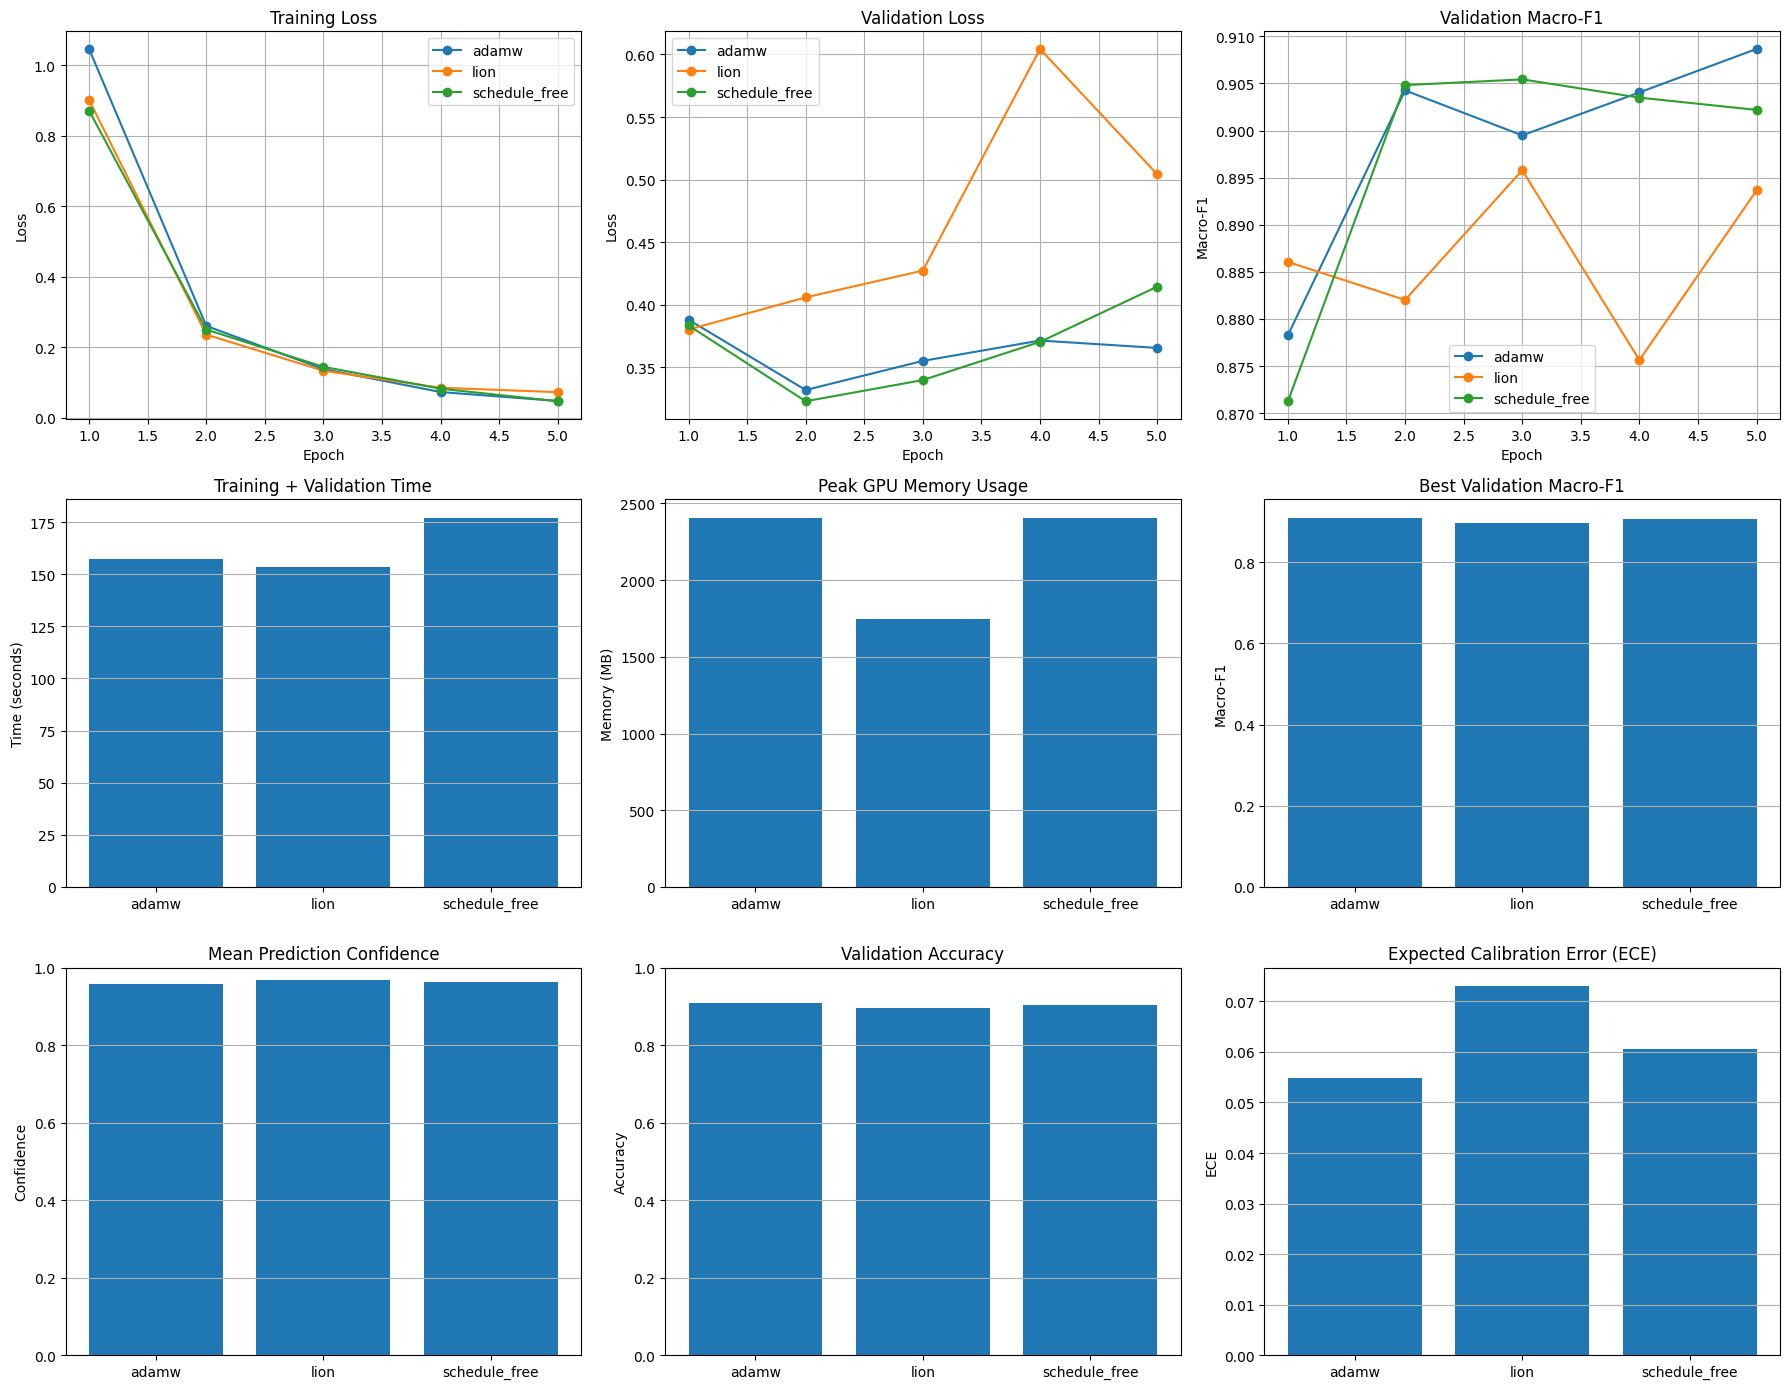

In [18]:
#visualize
visualize_comparison_results()

We observe that:
- **AdamW:** achieves the highest best validation macro-F1, the highest validation accuracy, and the lowest ECE. It appears to offer the best overall balance.
- **Lion:** has the lowest GPU memory use and shortest runtime, but weaker classification metrics and higher ECE.
- **Schedule-Free AdamW:** achieves classification results relatively close to AdamW, but takes longer to train and has a slightly higher ECE.

Based on this experiment, **AdamW appears to be the strongest option for classification quality**:
- It achieves a best validation macro-F1 of 0.9087 at epoch 5
- It achieves a validation loss at its minimum of 0.3319 at epoch 2
- It has the lowest ECE (0.0549), indicating the best calibration among the three optimizers in this run.

Other interesting remarks include:
- Lion's validation loss decreases substantially at the fifth epoch, accompanied by an increase in macro-F1. This suggests that **further training may improve its classification performance**. Testin different hyperparameters is also necessary.
- All three optimizers show decreasing training loss. However, the divergence between training and validation loss may indicate **overfitting**. This occurs when a model "memorizes" patterns specific to its training data that do not generalize well to unseen examples. **Early stopping** can help mitigate overfitting by stopping training when validation performance ceases to improve.

These findings are preliminary, as each optimizer was evaluated in a single run and used different hyperparameters. Further experiments with multiple random seeds and consistent checkpoint selection would help establish the reliability of these differences.


## Conclusion

The aim of this notebook was to investigate whether the training of a Finnish intent classification model should be done with AdamW or with another optimizer. We compared AdamW, Lion, and Schedule-Free AdamW in terms of validation performance, training time, GPU memory usage, and confidence calibration.

Overall, the results suggest that the choice of optimizer involves a trade-off between **classification quality** and **computational efficiency**. AdamW achieved the strongest classification results and the lowest ECE in our experiments.

However, these findings should be **interpreted with caution**. Each optimizer was evaluated in a single run and the observed differences cannot be attributed solely to the optimizers themselves. Further experiments using multiple random seeds, more systematic hyperparameter tuning, and consistent checkpoint selection would help establisg the results. In addition, the relatively high prediction confidence would benefit from qualitative analysis. This way, we can define whether edge cases have high or low confidence, and help shape the real user experience in the product.

As a next step, we should investigate **inference-time optimization**, focusing on techniques such as different batch sizes, reduced numerical precision, and quantization. The aim is to determine whether we can reduce the time and computational resources while preserving classification quality. Together, these experiments will provide a more complete understanding of how to make Finnish intent classification both computationally efficient and reliable.